In [2]:
import numpy as np

import jax.numpy as jnp
from jax import jit, vmap, grad, jacfwd, hessian
import jax.random

import scipy.optimize
import matplotlib.pyplot as plt

import emcee
import corner
# import tensorflow_probability.substrates.jax as tfp
from bayesian_stats_course_tools.plotting import plot_contours


In [5]:
title = "# Fisher, Hamilton Monte Carlo, and JAX"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Fisher, Hamilton Monte Carlo, and JAX

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

## Fisher matrix

For a distribution $p(X | \theta)$ of a RV $X$, given a parameter $\theta$, the Fisher information tells us how much information $X$ can give us about $\theta$.



The Fisher information is defined as
\begin{align}
    I(\theta) &= \mathbf{E}_{p(X|\theta)}\left[\left.\left(\frac{\partial\log p(X|\theta)}{\partial\theta}\right)^2 \right| \theta\right] \\
    &=^* -\mathbf{E}_{p(X|\theta)}\left[\left.\frac{\partial^2 \log p(X|\theta)}{\partial\theta^2}\right|\theta\right]\ .
\end{align}
The second equality applies in most cases of relevance.


#### Example: 1d Gaussian with known variance

Let
$$
    \log p(X | \mu) = -\frac{1}{2}\frac{(X - \mu)^2}{\sigma^2} + \text{const}
$$
then
$$
    I(\mu) = \frac{1}{\sigma^2}
$$

Larger $\sigma$ means less information gained on $\mu$ by data $X$.


### Cramer-Rao bound

The variance of an estimator $\hat\theta$ is bounded from below by the inverse of the Fisher information for that parameter:
$$
    \text{Var}[\hat\theta] \geq \frac{1}{I(\theta)}\,.
$$


For $n$ idd Gaussian $\vec X\sim \mathcal{N}(\mu, \sigma^2 I_n)$, with known variance $\sigma^2$ and unknown mean $\mu$
$$
    \log p(\vec X |\mu) = -\frac{1}{2}\sum_i \frac{(X_i - \mu)^2}{\sigma^2} + \text{const}
$$
The Fisher informaton on $\mu$ is
$$
    I(\mu) = \frac{n}{\sigma^2}\,.
$$

The Cramer-Rao bound is therefore
$$
    \text{Var}[\hat\mu] \geq \frac{\sigma^2}{n}
$$
That means that the variance of the sample mean is the lowest possible variance of an estimator for the mean.

### Multivariate case

For multiple parameters $\vec\theta$, the generalisation is the Fisher information matrix
\begin{align}
    I_{ij}(\vec\theta) &= \mathbf{E}_{p(X|\vec\theta)}\left[\left.\left(\frac{\partial \log p(X|\vec\theta)}{\partial \theta_i}\right)\left(\frac{\partial\log p(X|\vec\theta)}{\partial \theta_j}\right)\right|\theta\right] \\
    &= -\mathbf{E}_{p(X|\vec\theta)}\left[\left.\frac{\partial^2 \log p(X|\vec\theta)}{\partial \theta_i\partial\theta_j}\right|\theta\right]
\end{align}

We can get an estimate of the covariance of the parameters $\vec\theta$ by taking the inverse of the Fisher information matrix:
$$
    \Cov[\vec\theta] = I(\vec\theta)^{-1}\,.
$$

This allows us to make predictions on what the constraints on the parameters are going to be before we take data. 

This is only exact in the case of Gaussian distributed parameters but even if not this is a useful tool to get an idea on what an experimental setup (as encoded in the likelihood) is expected to produce.

For the case of a Gaussian likelihood where the covariance $\Sigma$ does not depend on the parameters, this reduces to
$$
    I_{ij}(\vec\theta) = \sum_{kl}\frac{\partial\mu_k(\vec\theta)}{\partial\theta_i}(\Sigma^{-1})_{kl}\frac{\partial\mu_l(\vec\theta)}{\partial\theta_j}
$$

### Jeffreys prior

Another place where the Fisher information appears is the Jeffreys prior.

We have talked about uninformative priors a couple of times so far. 
We choose uninformative priors when we do not want our posteriors to be influenced by our choice of priors.


But what does uninformative mean? 

### Clicker

Consider a Gaussian likelihood $p(X | \mu, \sigma) = \frac{1}{\sqrt{2\pi\sigma^2}}\mathrm{e}^{-\frac{1}{2}\frac{(X - \mu)^2}{\sigma^2}}$ where the variance is also an unknown parameter we want to infer. We therefore need to choose a prior - how should we define it?
- We define a prior on $\sigma$: $p(\sigma)$.
- We define a different prior on $\sigma^2$: $p(\sigma^2)$.
- It doesn't matter whether we use $\sigma$ or $\sigma^2$, the prior is the same.


A flat prior in $\theta$ will not be flat for $\theta^2$ for example:

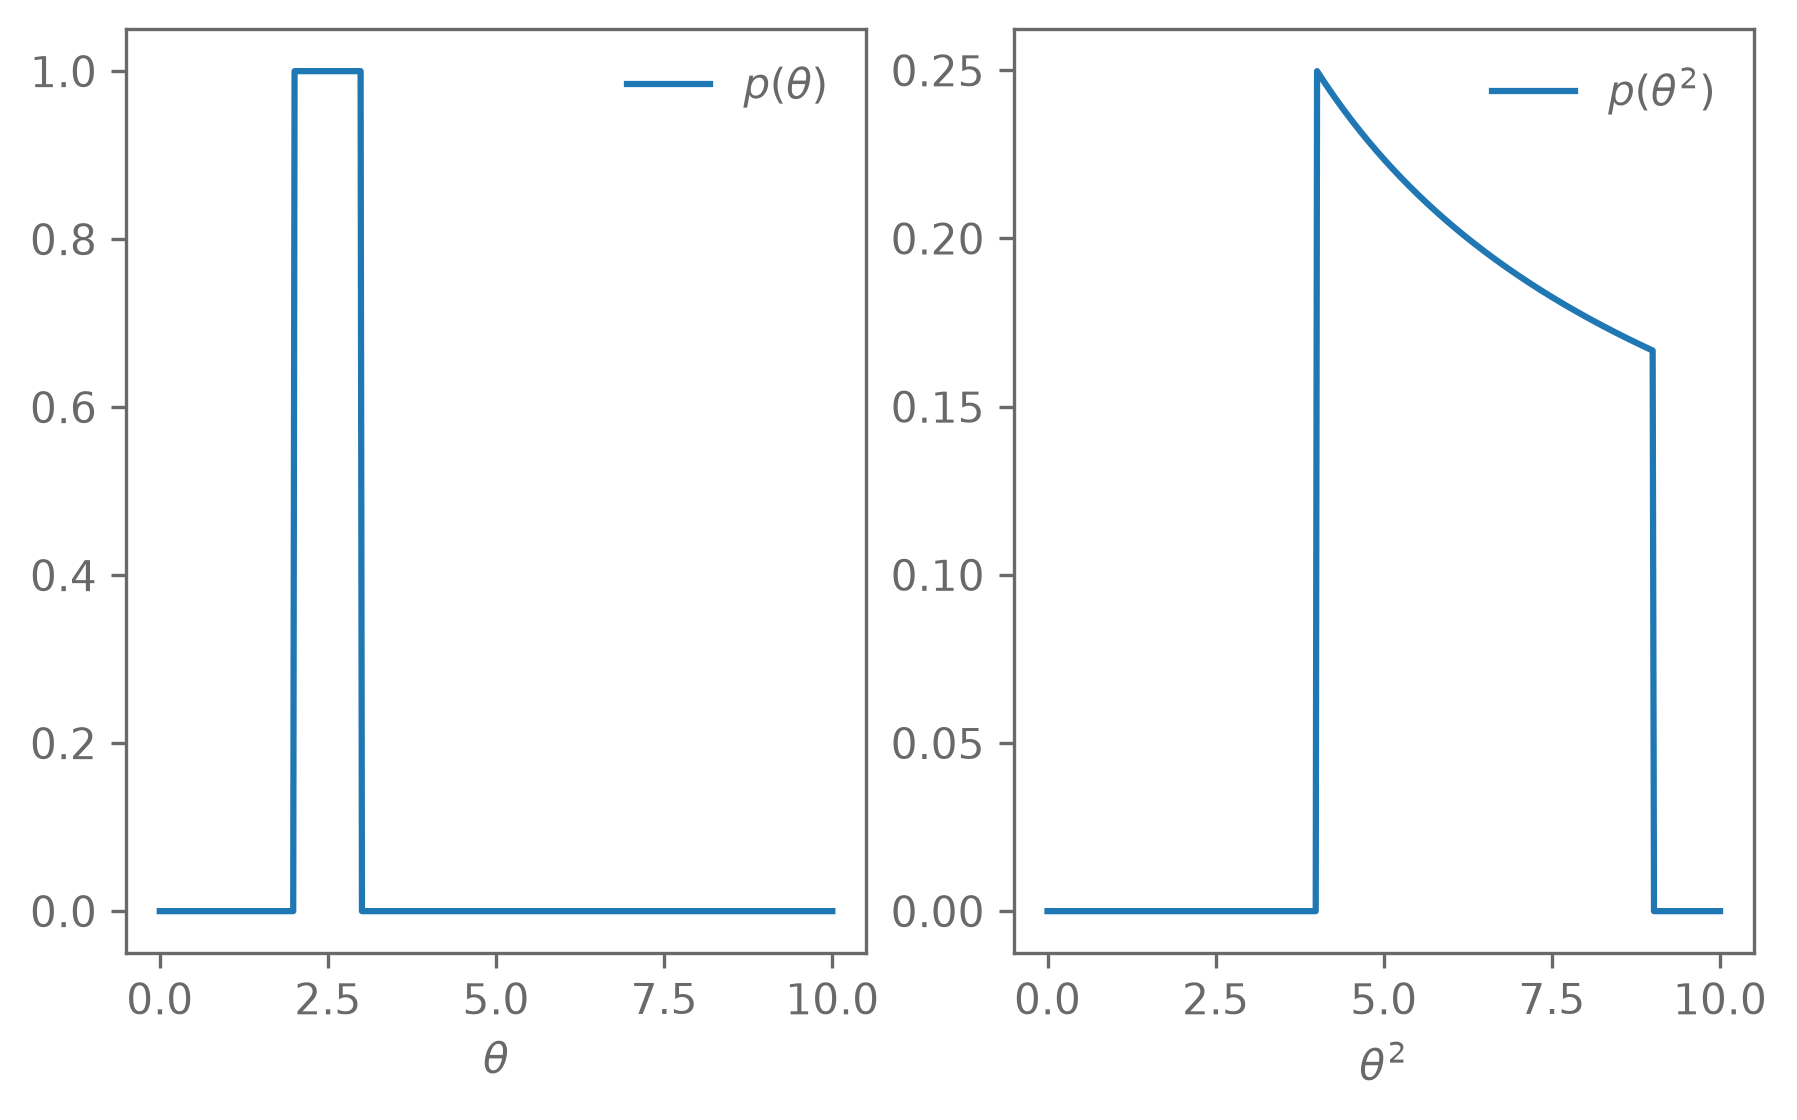

In [6]:
a, b = 2, 3
u = np.random.uniform(a, b, 10000)

fig, ax = plt.subplots(1, 2)

x = np.linspace(0, 10, 500)

p_u = np.piecewise(x, [(a < x) & (x < b)], [lambda x: 1/(b-a), 0])
p_u2 = np.piecewise(
    x, [(a < np.sqrt(x)) & (np.sqrt(x) < b)],
    [lambda x: 0.5*1/(b-a)/np.sqrt(x), 0]
)

ax[0].plot(x, p_u, label=r"$p(\theta)$")
ax[0].set_xlabel(r"$\theta$")
ax[0].legend()
ax[1].plot(x, p_u2, label=r"$p(\theta^2)$")
ax[1].set_xlabel(r"$\theta^2$")
ax[1].legend();

Jeffreys' priors address this, as they are constructed such that they are invariant to reparameterisation. This is achieved by setting the prior to
$$
    p(\theta) \propto \sqrt{\det I(\theta)}\,.
$$



This definition gives us the desired reparameterisation invariance, because under a reparameterisation $\theta \rightarrow \rho$, the Fisher information transforms as
$$
    I(\rho) = I(\theta)\left(\frac{\dd \theta}{\dd\rho}\right)^2\ ,
$$
while the change of variables transforms the distribution $p(\theta)$ as
$$
    p(\rho) = p(\theta)\left|\frac{\dd\theta}{\dd\rho}\right|\ .
$$



By choosing $p(\theta) \propto \sqrt{\det I(\theta)}$, we also have $p(\rho) \propto \sqrt{\det I(\rho)}$, the invariance to reparameterisation we are looking for.

#### Example: Jeffreys prior for mean and variance

As we have seen before, the Fisher information of the mean of Gaussian is
$$
    I(\mu) = \frac{1}{\sigma^2}
$$
The Jeffreys prior for $\mu$ is therefore
$$
    p(\mu) \propto \frac{1}{\sigma} \propto \text{const}\ ,
$$
i.e., it does not depend on $\mu$. So for the mean (or location parameters in general), a flat prior is appropriate.



Note that the constant prior is not a probability distribution, since it cannot be normalised. 
It is an improper prior. In this case the posterior is still well-defined though.

In practice there are usually physical limits on the parameter, which addresses this.

Now, the case where $\mu$ is fixed but $\sigma$ is a parameter:
$$
    I(\sigma) = \frac{2}{\sigma^2}
$$
This gives the Jeffreys prior for the standard deviation (and scale parameters in general)
$$
    p(\sigma) \propto \frac{1}{\sigma}
$$



This is also equivalent to having a flat prior on $\log \sigma$: $p(\log\sigma)\propto \text{const}$. 

The intuition is that if there is no information on the scale of something, then the probability of it being in the range 1-10 or 10-100 should be the same. This corresponds to a flat prior on a log scale.



Now the prior depends on $\sigma$ and is not a flat prior. This is again an improper prior, and depending on the likelihood, it might lead to an ill-defined posterior.

Summary:
- How models are parametrised matters.
- If this affects your analysis, consider using Jeffreys' priors.
- For multiple parameters, this can be generalised to so-called reference priors.
    - These can be difficult to define in practise.
- These priors are often improper, so some physical insight or other prior knowledge needs to be included in most cases anyways.

### Clicker

In the multivariate case, the Fisher information matrix $I_{ij}(\vec{\theta})$ is given by the expectation of the product of partial derivatives of the log-likelihood with respect to the parameters $\theta_i$ and $\theta_j$. What does the inverse of this matrix represent?
 - The gradient of the likelihood.
 - An estimate of the covariance of $\vec{\theta}$.
 - The information density of each parameter.
 - The posterior distribution of $\vec{\theta}$.

## JAX

[JAX](https://jax.readthedocs.io) brings autodifferentiation to numpy and allows it to run fast on CPUs, GPUs, etc.

I will go briefly over the main features here but I suggest you have a look at the [tutorial](https://jax.readthedocs.io/en/latest/jax-101/01-jax-basics.html) (or others, in case you find something better) to get a feel for the features.

### Autodifferentiation

The code we run on computers ultimatively is just a sequence of elementary operations, such as addition and multiplication.

If we can track all the operations a function executes internally, we can use the chain rule to compute the derivatives of the function.

Autodifferentiation frameworks do the hard work for us by tracking all the operations from our code down to the elementary operations and giving us access to derivatives.

In [7]:
from jax import grad

# Define our function
def f(x):
    return x**2 - 1

# jax.grad takes a function and returns another function, which is the gradient
df_dx = grad(f)
d2f_dx2 = grad(df_dx)

x = 1.0
print(f"f({x}) = {f(x)}")
print(f"df({x})/dx = {df_dx(x)}")
print(f"d^2f({x})/dx^2 = {d2f_dx2(x)}")

f(1.0) = 0.0
df(1.0)/dx = 2.0
d^2f(1.0)/dx^2 = 2.0


### Auto-vectorisation

JAX also gives a convenient utility to vectorise our functions.

In [8]:
from jax import vmap

# Define a vectorised version of our derivative df/dx
batched_df_dx = vmap(df_dx)

batched_df_dx(jnp.array([1.0, 2.0]))

Array([2., 4.], dtype=float32)

### Just-in-time compilation

Finally, JAX allows compiling functions to run fast on CPUs, as well as GPUs. 
This puts some [mild restrictions](https://jax.readthedocs.io/en/latest/jax-101/02-jitting.html) on how your code needs to be structured (see also https://jax.readthedocs.io/en/latest/notebooks/Common_Gotchas_in_JAX.html).

In [9]:
from jax import jit

jitted_batched_df_dx = jit(batched_df_dx)

# For complex functions, this can me MUCH faster
jitted_batched_df_dx(jnp.array([1.0, 2.0]))

Array([2., 4.], dtype=float32)

### Random numbers

The way that JAX handles random numbers is a bit different to how they are being handled in other frameworks, such as numpy. 

For details, have a look at https://jax.readthedocs.io/en/latest/jax-101/05-random-numbers.html

The core is that instead of setting a seed once and each subsequent call to a function that generates random numbers advances the seed automatically, each random function needs to be given an explicit key.

New keys are generated by splitting an existing key:

In [10]:
key = jax.random.PRNGKey(42)

key, sub_key = jax.random.split(key)

### Example: gradients of a log probability

In [11]:
# Define variances and correlation
sigma_x = 1.5
sigma_y = 1
rho = 0.85

# Define mean and covariance
mean = jnp.array([0.0, 0.0])
cov = jnp.array([[sigma_x**2, sigma_x*sigma_y*rho],
                 [sigma_x*sigma_y*rho, sigma_y**2]])
cov_inv = jnp.linalg.inv(cov)

# Define grids for plotting
x_grid = jnp.linspace(-5, 5, 15)
y_grid = jnp.linspace(-3, 3, 10)
xx, yy = jnp.meshgrid(x_grid, y_grid)
coords = jnp.dstack((xx, yy)).reshape(-1, 2)

In [12]:
def log_pdf(x):
    r = x - mean
    return -0.5 * r @ cov_inv @ r

# Compute the gradients
grads = vmap(grad(log_pdf))(coords)

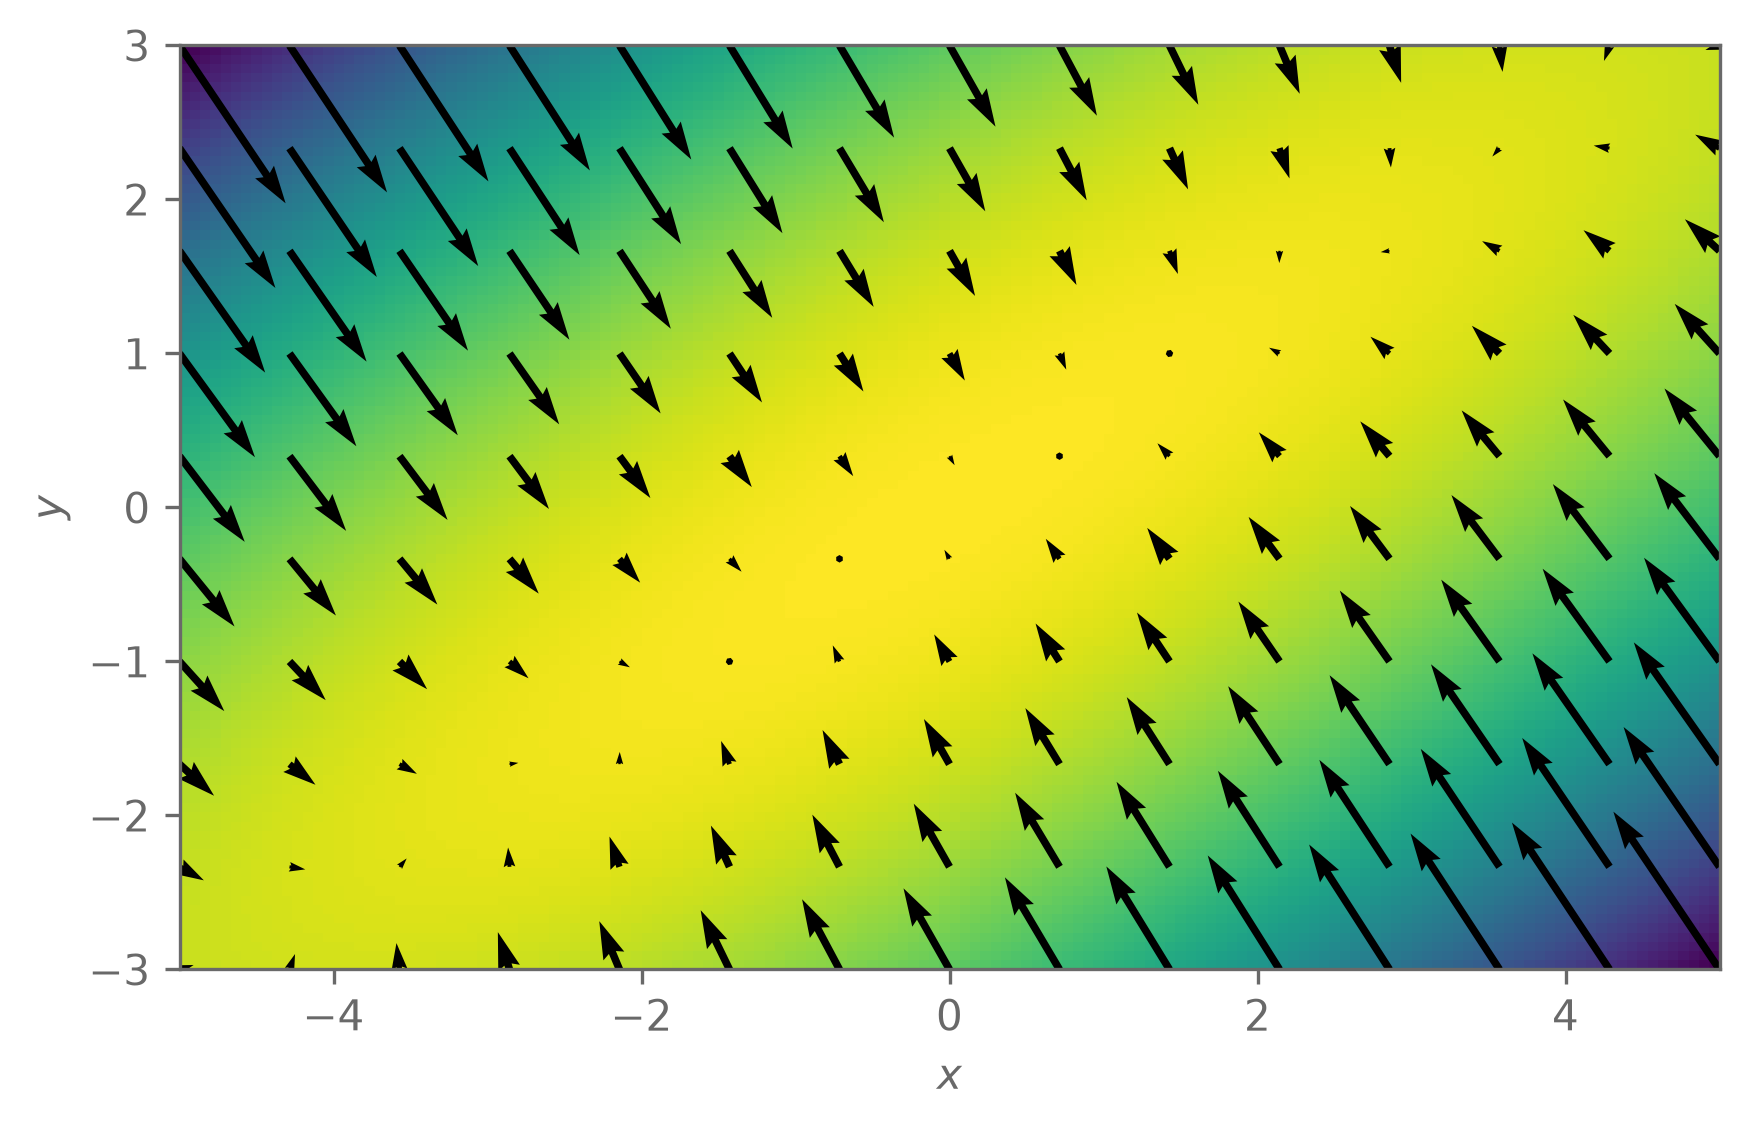

In [13]:
x_grid_fine = jnp.linspace(-5, 5, 150)
y_grid_fine = jnp.linspace(-3, 3, 100)
coords_fine = jnp.dstack(jnp.meshgrid(x_grid_fine, y_grid_fine)).reshape(-1, 2)

plt.imshow(
    vmap(log_pdf)(coords_fine).reshape(y_grid_fine.size, x_grid_fine.size),
    extent=(x_grid[0], x_grid[-1], y_grid[0], y_grid[-1]), origin="lower")
plt.quiver(*coords.T, *grads.T)
plt.xlabel("$x$")
plt.ylabel("$y$");

### Example: Fisher information of the Jovian moon data

We can use the Fisher information matrix to predict what kind of constraints we can expect from our data. For complex and computationally expensive likelihoods this is a useful to get a rough estimate of the contraints without having to run an expensive MCMC.

Let us go back to the Jovian moon example.

In [15]:
moon = "Io"
t, distance, distance_alt, distance_err = np.loadtxt(
    f"../lectures/data/jovian_moons/{moon}.dat", unpack=True)

# Use the offset between the distance estimates as an extra error
cov = np.diag(distance_err**2 + (distance-distance_alt)**2)
inv_cov = np.linalg.inv(cov)

In [16]:
def model(theta, t):
    semimajor, period, phi = theta
    return semimajor * jnp.sin(2*np.pi/period * t + phi)

def log_likelihood(theta):
    mu = model(theta, t=t)
    r = distance - mu
    return -0.5 * r @ inv_cov @ r

def log_prior(theta):
    # Use flat priors for now
    return 0

def log_posterior(theta):
    return log_likelihood(theta) + log_prior(theta)

In [17]:
theta_MAP = scipy.optimize.minimize(
    fun=lambda x: -log_posterior(x),
    jac=grad(lambda x: -log_posterior(x)),  # We can use JAX's autodifferentiation
                                            # to use gradient-based optimisation
                                            # methods.
    method="L-BFGS-B",
    x0=(1.0, 40.0, 1.0),
).x

semimajor_MAP, period_MAP, phase_MAP = theta_MAP
print("MAP results")
print(f"{semimajor_MAP=:.3f}, {period_MAP=:.3f}, {phase_MAP=:.3f}")

MAP results
semimajor_MAP=0.419, period_MAP=42.324, phase_MAP=2.912


Because we use a Gaussian likelihood with parameter-independent covariance
$$
    I_{ij}(\vec\theta) = \sum_{kl}\frac{\partial\mu_k(\vec\theta)}{\partial\theta_i}(\Sigma^{-1})_{kl}\frac{\partial\mu_l(\vec\theta)}{\partial\theta_j}
$$

In [18]:
jacobian = jacfwd(model)(theta_MAP, t)

fisher_I = np.einsum("ip,ij,js", jacobian, inv_cov, jacobian)

fisher_cov = np.linalg.inv(fisher_I)

print(f"Expected uncertainty on a: {np.sqrt(cov[0,0]):.4f}")
print(f"Expected uncertainty on T: {np.sqrt(cov[1,1]):.3f}")

Expected uncertainty on a: 0.0087
Expected uncertainty on T: 0.010


In [19]:
n_param = 3
n_walker = 10
n_step = 8000

# The starting point for each walker
theta_init = np.array([0.5, 40.0, 3.0]) \
    + 0.1*np.random.normal(size=(n_walker, n_param))

sampler = emcee.EnsembleSampler(
    nwalkers=n_walker, ndim=n_param,
    log_prob_fn=jit(vmap(log_posterior)),
    vectorize=True
)
state = sampler.run_mcmc(theta_init, nsteps=n_step, progress=True)

print("Auto-correlation time:")
for name, value in zip(["a", "T", "phi"], autocorr_time := sampler.get_autocorr_time()):
    print(f"{name} = {value:.1f}")

chain = sampler.get_chain(
    discard=int(5*max(autocorr_time)),
    thin=int(max(autocorr_time)/4),
    flat=True
)

100%|██████████| 8000/8000 [00:02<00:00, 3146.36it/s]

Auto-correlation time:
a = 36.3
T = 47.8
phi = 45.0


How does the Fisher estimate of the parameter covariance compare to the posteriors we get from a MCMC?

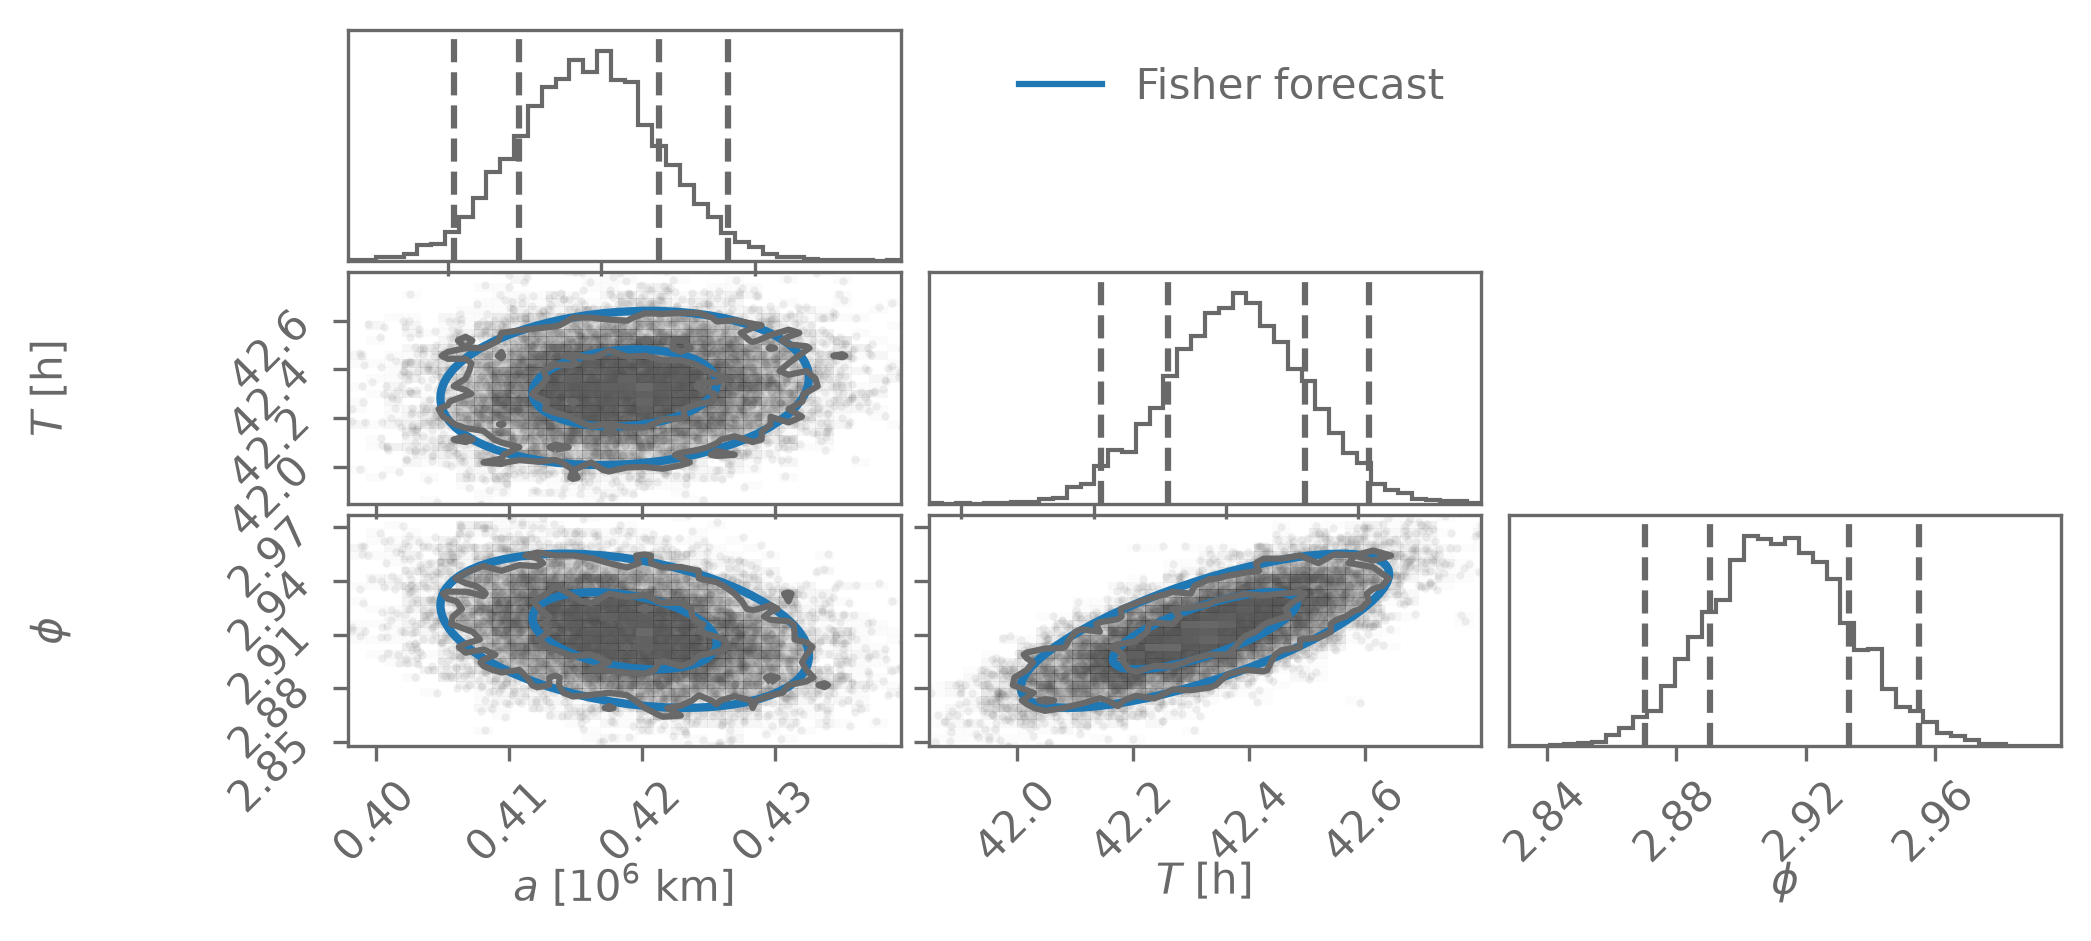

In [20]:
fig = plt.figure()
fig = corner.corner(
    chain,
    bins=40,
    labels=["$a$ [$10^6$ km]", "$T$ [h]", r"$\phi$"],
    levels=1-np.exp(-0.5*np.array([1, 2])**2),
    quantiles=[0.025, 0.16, 0.84, 0.975],
    labelpad=0.2,
    fig=fig
)
fig.subplots_adjust(bottom=0.35)

for idx, ax in zip([[0, 1], [0, 2], [1, 2]], [fig.axes[3], fig.axes[6], fig.axes[7]]):
    plot_contours(cov=fisher_cov[np.ix_(idx, idx)], pos=theta_MAP[idx], nstd=1, fill=False, ax=ax, color="C0", linewidth=2)
    plot_contours(cov=fisher_cov[np.ix_(idx, idx)], pos=theta_MAP[idx], nstd=2, fill=False, ax=ax, color="C0", linewidth=2)

fig.axes[1].plot([], [], color="C0", label="Fisher forecast")
_ = fig.axes[1].legend(frameon=False)

The Fisher information matches the posterior well. One reason is that we did not include any prior information. 



Instead of the Fisher information (which is the expectation over the Hessian of the log likelihood), we might just want to get a Gaussian approximation of the posterior.

Expand the log-posterior around the posterior mode $\vec \theta^*$:
$$
    \log p(\vec\theta | \vec d) = \log p(\vec \theta^* | \vec d) + \frac{1}{2}(\vec \theta - \vec \theta^*)_i\left(\frac{\partial^2}{\partial\theta_i\partial\theta_j}\log p(\vec \theta|\vec d)\right)_{\vec \theta=\vec \theta^*}(\vec \theta - \vec \theta^*)_j\,.
$$
The term $\propto (\vec \theta - \vec \theta^*)$ is zero at the mode.

From this expansion we see that the posterior can be approximated by 
$$
    p(\vec\theta | \vec d) \approx \mathcal{N}(\vec\theta^*, I(\vec\theta^*)^{-1})\,,
$$
where the _observed_ information $I(\vec\theta)$ is given by
$$
    I(\vec\theta) = -\frac{\partial^2}{\partial\theta_i\partial\theta_j}\log p(\vec \theta|\vec d)\,.
$$

In [21]:
# JAX makes this very easy
posterior_observed_information = -hessian(log_posterior)(theta_MAP)
posterior_covariance_estimate = np.linalg.inv(posterior_observed_information)

# Exercise 1

For the linear model $y_i \sim \mathcal N(mx_i + b, \sigma_i^2)$ and data from `../lectures/data/linear_fits/data_0.txt` do the following:

1. Analytically calculate the FIM using either the Hessian definition or the grad definition.
2. Write a function that calculates this based on the $x$-values and $\sigma$.
3. Implement the likelihood in JAX and use `jax.hessian` or `jax.grad` to calculate the FIM and compare to (2). If you use `jax.hessian`, check that properties of the analytic FIM propagate here (e.g. whether it is independent of certain variables).

## Hamiltonian Monte Carlo

Hamiltonian Monte Carlo is an MCMC algorithm that scales well to high dimensions. 

The downside is that it requires the gradient of the log probability. But with JAX we can get that easily now.

Hamilton Monte Carlo casts the sampling problem as a physics problem of exploring a potential using Hamiltonian dynamics.


 
We define a Hamiltonian
$$
    H(\vec x, \vec p) = U(\vec x) + K(\vec p)
$$
with potential $U(\vec x)$ at position $\vec x$ and kinetic energy $K(\vec p) = \frac{1}{2}\vec p^T M^{-1}\vec p$ of momentum $\vec p$ with mass matrix $M$.



From this we can define a probability
$$
    p_H(\vec x, \vec p) = \frac{1}{Z}\ee^{-H(\vec x, \vec p)} = \frac{1}{Z}\ee^{-U(\vec x)}\ee^{-K(\vec p)}
$$
The positions and momenta are independent, such that the marginal distribution of $\vec x$ is
$$
    p(\vec x) \propto \ee^{-U(\vec x)}
$$
This is the distribution we want to sample from. To do this, we define $U(\vec x) = -\log p(\vec x)$.

Hamiltonian dynamics are defined by the equations of motion
\begin{align}
    \frac{\dd x_i}{\dd t} &= \frac{\partial H}{\partial p_i} \\
    \frac{\dd p_i}{\dd t} &= -\frac{\partial H}{\partial x_i} \\
\end{align}

In our case we have
\begin{align}
    \frac{\dd x_i}{\dd t} &= \frac{\partial K}{\partial p_i} = (M^{-1}\vec p)_i \\
    \frac{\dd p_i}{\dd t} &= -\frac{\partial U}{\partial x_i} \\
\end{align}


Hamiltonian Monte Carlo works as follows:

Start at $\vec x_0$.
1. Sample $\vec p_0$ from a Gaussian with mean 0 and covariance $M$: $\vec p_0\sim\mathcal{N}(0, M)$
2. Evolve $\vec x$ and $\vec p$ with the dynamics defined by the Hamiltonian using the leap frog algorithm
3. Accept the new position using a Metropolis-Hastings acceptance criterion based on the integration error of the Hamiltonian


The leap frog algorithm is a method to integrate the equation of motion to evolve the system a small amount $\epsilon$ from time $t$ to time $t+\epsilon$.

1. Evolve the momentum a half step: $\vec p_{t+\epsilon/2} = \vec p_\epsilon - \frac{\epsilon}{2}\nabla U(\vec x_t)$
2. Evolve the position by a full step: $\vec x_{t+\epsilon} = \vec x_t + \epsilon M^{-1} \vec p_{t+\epsilon/2}$
3. Evolve the momentum another half step: $\vec p_{t+\epsilon} = \vec p_{t+\epsilon/2} - \frac{\epsilon}{2}\nabla U(\vec x_{t+\epsilon})$

Repeat this for $L$ steps to move from the state $\vec x_\mathrm{old}, \vec p_\mathrm{old}$ to $\vec x_\mathrm{new}, \vec p_\mathrm{new}$.


Then accept the new state $\vec x_\mathrm{new}, \vec p_\mathrm{new}$ with probability
$$
    a = \min\left(1, \frac{\ee^{-H(\vec x_\mathrm{new}, \vec p_\mathrm{new})}}{\ee^{-H(\vec x_\mathrm{old}, \vec p_\mathrm{old})}}\right)\,.
$$

If the equations of motions are solved exactly, the Hamiltonian is conserved, and the acceptance probability is always 1.

In practice, we get an integration error, which depends on the step size $\epsilon$ and number of steps $L$. These are the main tuning parameters.



For the integration to be stable, $\epsilon$ needs to be smaller than the smallest length scale in the distribution we want to sample.

The number of steps should be chosen such that $L\epsilon$ is long enough to cover the longest length scale. 

This can present problems if you use a global step size and different parameters in the problem are on different scales. This means that HMC-based methods sometimes need variable transformations to rescale some large or small parameters.

In addition, the mass matrix $M$ can be chosen to align the momenta better with the shape of the distribution.

In [22]:
def sample_hmc(x0, log_pdf, n, L, epsilon, mass_matrix, key):

    mass_matrix_inv = jnp.linalg.inv(mass_matrix)

    # Define the potential and Hamiltonian
    def U(x):
        return -log_pdf(x)

    def H(x, p):
        return U(x) + 0.5 * p @ mass_matrix_inv @ p

    # Use JAX to get the gradient of U
    grad_x_U = grad(U)

    # The leap frog integrator. We speed this up using just-in-time compilation
    @jit
    def leap_frog(x, p):
        t = [x]
        for _ in range(L):
            p_prime = p - epsilon/2 * grad_x_U(x)
            x = x + epsilon * mass_matrix_inv @ p_prime
            p = p_prime - epsilon/2 * grad_x_U(x)
            t.append(x)
        return x, p, jnp.array(t)
    
    samples = [x0]
    trajectories = []
    n_accpeted = 0
    for _ in range(n):
        key, subkey = jax.random.split(key)
        # Sample a new momentum
        p0 = jax.random.multivariate_normal(
            subkey, mean=jnp.zeros_like(x0), cov=mass_matrix
        )
        # Integrate Hamiltonian dynamics
        x, p, t = leap_frog(x0, p0)

        # Metropolis-Hastings step
        a = min(1, jnp.exp(H(x0, p0) -  H(x, p)))

        key, subkey = jax.random.split(key)
        u = jax.random.uniform(subkey)
        if a >= u:
            x0 = x
            n_accpeted += 1
        
        samples.append(x0)
        trajectories.append(t)
    
    acceptance_rate = n_accpeted/n
    return jnp.array(samples), trajectories, acceptance_rate

In [23]:
# Setup our PRNG keys
key, subkey = jax.random.split(jax.random.PRNGKey(42))

samples, trajectories, acceptance_rate = sample_hmc(
    x0=jnp.array([0.0, 2.0]),
    log_pdf=log_pdf,
    n=30,
    L=20, epsilon=0.2, mass_matrix=jnp.eye(2),
    key=subkey
)
print(f"Acceptance rate: {acceptance_rate:.3f}")

Acceptance rate: 1.000


In [24]:
from matplotlib.collections import LineCollection
from matplotlib.animation import ArtistAnimation
from IPython.display import HTML

fig, ax = plt.subplots()

levels = 1-np.exp(-0.5*np.array([1, 2])**2)

def pdf(x):
    return jnp.exp(log_pdf(x))

ax.contour(
    vmap(pdf)(coords_fine).reshape(y_grid_fine.size, x_grid_fine.size)/pdf(mean),
    extent=(x_grid[0], x_grid[-1], y_grid[0], y_grid[-1]), origin="lower",
    levels=(1-levels)[::-1], colors="grey", linewidths=1)

ax.set_xlim(-5, 5)
ax.set_ylim(-3, 3)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")

trail_length = 10
alpha = np.linspace(0.0, 1, trail_length)[::-1]

artists = []

sample_points = []

for s, t in zip(samples, trajectories):
    sample_points += ax.plot(*s, marker="o", ms=3, c="C3")

    for i in range(t.shape[0]+trail_length//2):
        trail = t[max(0, i-trail_length): min(i, t.shape[0])]
        n = trail.shape[0]
        colors = np.zeros((n, 4))
        colors[:, 3] = alpha[:n][::-1]

        points = trail.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        collection = LineCollection(segments, colors=colors)
        
        artists.append(sample_points + [ax.add_collection(collection)])
    
hmc_sampling_ani = ArtistAnimation(fig, artists=artists, interval=70, blit=True)
plt.close()
# HTML(hmc_sampling_ani.to_jshtml())
hmc_sampling_ani.save(filename="../hmc.webp", writer="pillow")

![hmc](../assets/hmc.webp)

The tuning steps are important but can be tedious. Mature implemetations, such as the no-U-turn algorithm (NUTS) with automatic tuning are available.

Here is an implementation in `tensorflow_probability`. This works without the need for `tensorflow` thanks to the JAX backend.

In [25]:
import tensorflow_probability.substrates.jax as tfp

num_results = 2000
num_burnin_steps = 1000

# Set the adaptation strategy...
adaptive_hmc = tfp.mcmc.DualAveragingStepSizeAdaptation(
    # ... for the sampler, which is NUTS here
    tfp.mcmc.NoUTurnSampler(
        target_log_prob_fn=jax.jit(jax.vmap(log_pdf)), # The target distribution
        step_size=1.),
    num_adaptation_steps=int(num_burnin_steps * 0.8) # How many steps to use for tuning
)

AttributeError: module 'jax.interpreters.xla' has no attribute 'pytype_aval_mappings'

In [ ]:
def run_chain(seed):
    # Run the chain (with burn-in).
    samples, info = tfp.mcmc.sample_chain(
        num_results=num_results,
        num_burnin_steps=num_burnin_steps,
        current_state=jnp.array([0.0, 0.0]), 
        kernel=adaptive_hmc,
        trace_fn=lambda _, pkr: (pkr.inner_results.target_log_prob, pkr.inner_results.is_accepted),
        seed=seed
    )

    log_prob, is_accepted = info
    print(f"Acceptance rate: {is_accepted.sum()/is_accepted.size}")
    return samples, log_prob

samples, log_prob = run_chain(seed=jax.random.PRNGKey(42))

Acceptance rate: 0.8622499704360962


## Probabilistic programming

We now introduce a probabilistic programming framework built on `JAX` called `numpyro`. It's very useful for any kind of models, but especially hierarchical models.

In probabilistic programming, variables in our programs are random variables. 
We specify their distributions and the probabilistic programming framework takes care of propagating the distributions.

This will be a very brief introduction. For a slightly more detailed introduction, have a look at https://dfm.io/posts/intro-to-numpyro/.

To illustrate how this works, we first revisit the linear-fit data set with homoscedastic errors in `data/linear_fits/data_0.txt`.

We assume a Gaussian likelihood with $\mu(x) = m x + b$ and uncertainty $\sigma_y$:
$$
    y_i \sim \mathcal{N}(\mu(x_i), \sigma_y^2) \,.
$$

The parameters $m$ and $b$ both have Gaussian priors:
$$
    p(m) = \mathcal{N}(1, 1) \\
    p(b) = \mathcal{N}(0, 1.2^2)
$$

Our probabilistic model is then
\begin{align}
    m &\sim \mathcal{N}(1, 1) \\
    b &\sim \mathcal{N}(0, 1.2^2) \\
    y_i &\sim \mathcal{N}(m x_i + b, \sigma_y^2)
\end{align}

In probabilistic programming frameworks we can specify such a model and then condition it on the actual observed data $y^\mathrm{obs}_i$.


Instead of writing down (log) probability functions for the priors and likelihood to sample from the posterior, we can write down the model just in terms of its random variables, their distributions, and how they are related, and the probabilistic programming framework takes care of tracking all the probabilities.

In [4]:
x_obs, y_obs, y_err = np.loadtxt("../lectures/data/linear_fits/data_0.txt", unpack=True)
# For now, all errors are the same
sigma_y = y_err[0]

def plot_linear_data_set(x, y, y_err=None):
    """Plot linear data set and format the plot."""
    fig, ax = plt.subplots(1, 1)

    if y_err is not None:
        ax.errorbar(x, y, y_err, fmt=".", label="Data")
    else:
        ax.plot(x, y, marker=".", linestyle="none", label="Data")

    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.legend(loc="upper left")

    return fig, ax

In [5]:
import numpyro
import numpyro.distributions as distr

# Our probabilistic model needs to be defined as a function
def model(y_obs=None):
    # The parameters are drawn from the prior distributions
    m = numpyro.sample("m", distr.Normal(loc=1, scale=1))
    b = numpyro.sample("b", distr.Normal(loc=0, scale=1.2))

    # We save the mean predictions using the numpyro.deterministic primitive
    mu = numpyro.deterministic("mu", m*x_obs + b)

    # At the end we draw the observations and condition them on the actual
    # observed data
    numpyro.sample("obs", distr.Normal(loc=mu, scale=sigma_y), obs=y_obs)

Once we have the model specified, we can create samples from the prior predictive distribution.

In [6]:
master_key = jax.random.PRNGKey(42)
rng_key, master_key = jax.random.split(master_key)

prior_predictive = numpyro.infer.Predictive(model=model, num_samples=10)
prior_predictive_samples = prior_predictive(rng_key=rng_key)["obs"]

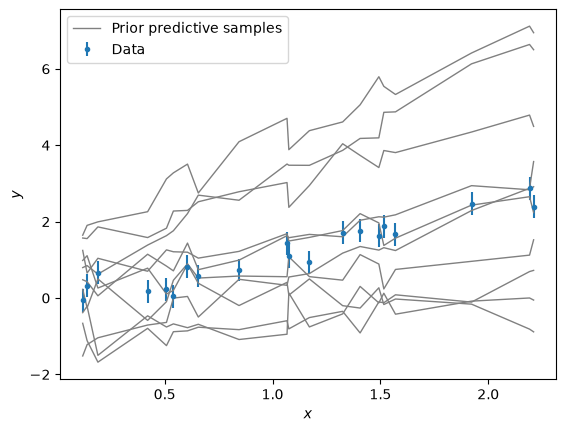

In [7]:
fig, ax = plot_linear_data_set(x_obs, y_obs, y_err)
ax.plot(x_obs, prior_predictive_samples.T, c="grey", lw=1)
ax.plot([], [], c="grey", lw=1, label="Prior predictive samples")
ax.legend();

To get the posterior, we can use the build in NUTS HMC sampler.

In [8]:
rng_key, master_key = jax.random.split(master_key)

# Run NUTS
kernel = numpyro.infer.NUTS(model)
num_samples = 2000
mcmc = numpyro.infer.MCMC(kernel, num_warmup=1000, num_samples=num_samples)
mcmc.run(
    rng_key, y_obs=y_obs
)
mcmc.print_summary()
samples = mcmc.get_samples()

sample: 100%|██████████| 3000/3000 [00:01<00:00, 2671.90it/s, 1 steps of size 3.46e-01. acc. prob=0.95] 


                mean       std    median      5.0%     95.0%     n_eff     r_hat
         b     -0.14      0.12     -0.14     -0.34      0.06    510.89      1.00
         m      1.25      0.10      1.25      1.10      1.43    505.71      1.00

Number of divergences: 0


From here we can look at the posterior samples, or get the posterior predictive distribution:

In [9]:
rng_key, master_key = jax.random.split(master_key)

posterior_predictive = numpyro.infer.Predictive(model=model, posterior_samples=samples)
posterior_predictive_samples = posterior_predictive(rng_key=rng_key)["obs"]

model_predictive_samples = samples["mu"]

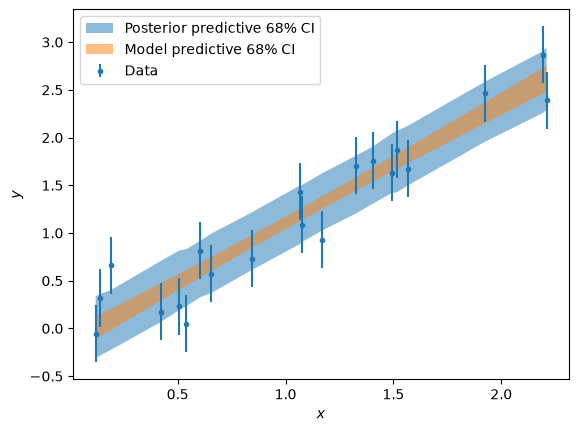

In [10]:
fig, ax = plot_linear_data_set(x_obs, y_obs, y_err)

ax.fill_between(x_obs, *np.quantile(posterior_predictive_samples, [0.16, 0.84], axis=0), alpha=0.5, label="Posterior predictive 68% CI")
ax.fill_between(x_obs, *np.quantile(model_predictive_samples, [0.16, 0.84], axis=0), alpha=0.5, label="Model predictive 68% CI")
ax.legend();

# Hierarchical models and probabilistic programming

We encounted a hierarchical model last week, when discussing linear regression.

We will have data points $y_{ij}$ where $j$ labels a **group** and $i$ labels a value within that group.

Imagine we have schools across several cities and we are looking at their test scores. $j$ might label the city, and $i$ would label the specific school.

Let's construct a model where schools in the same city have a similar mean test score, $\theta_j$. But across the country, those means are themselves drawn from a Gaussian distribution.

We'll write it out in a form you'll often see:

$y_{ij} \sim \mathcal N_y(\theta_j, \sigma_{ij}^2)$
$\theta_j \sim \mathcal N_\theta(\mu, \tau^2)$
$\mu \sim \mathcal U(0, 100)$
$\log_{10} \tau \sim \mathcal U(-2, 2)$

where we used the Jeffreys prior on $\tau$.


The data are in `lectures/data/fake_school_data.txt`: 20 cities with 10 schools each.
The file has 40 columns that alternate between the scores of the schools in a city and the variances $\sigma_{ij}^2$ of those scores
(column 1: scores in city 1, column 2: variances in city 1, column 3: scores in city 2, ...).

1. Implement this model in `numpyro`.
2. Sample the posterior of $\mu$, $\tau$ and the $\theta_j$ with NUTS.
3. Compare the posterior means of the $\theta_j$ with the per-city average scores. What does the hierarchical model do to them?
4. Since $\mu$ and $\tau$ are random variables, the prior on $\theta_j$'s now has uncertainty. Draw from the posterior samples, and for each draw, plot the prior on the $\theta_j$'s conditioned on the data. 

In [ ]:
# Notation:
#   n_city             number of cities (groups), here 20
#   n_school_per_city  number of schools per city, here 10
school_table = np.loadtxt("data/fake_school_data.txt")  # (n_school_per_city, 2 * n_city)

# Columns alternate (scores, variances) per city; transpose so cities are rows
scores = school_table[:, 0::2].T           # (n_city, n_school_per_city)
score_variances = school_table[:, 1::2].T  # (n_city, n_school_per_city)
score_sigmas = np.sqrt(score_variances)    # (n_city, n_school_per_city)

n_city, n_school_per_city = scores.shape
print(f"{n_city} cities with {n_school_per_city} schools each")

20 cities with 10 schools each
